# Practica 7 agrupamiento con K-Means

Se agrupan los registros por temperatura, nubosidad y volumen de trafico

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

path = "../data/procesed/metro.csv"
metro = pd.read_csv(path)
metro.head()

Fontconfig warning: We will not regenerate the cache because some cache files were generated by a newer version (0x2012003) of Fontconfig. Please regenerate the cache with the latest version of Fontconfig to avoid any unexpected behavior. (current version: 0x2012002)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40.0,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 13:00:00,4918


Datos para el modelo

Se deja un registro por fecha y hora y se escalan las variables para comparar sus distancias

In [2]:
columnas = ["temp", "clouds_all", "traffic_volume"]
datos = metro.drop_duplicates(subset="date_time")
datos = datos.dropna(subset=columnas).copy()
x = datos[columnas]

escalador = StandardScaler()
x_scaled = escalador.fit_transform(x)

Modelo K-Means

Se usan 3 grupos como punto de partida

In [3]:
modelo = KMeans(n_clusters=3, random_state=42, n_init=10)
datos["grupo"] = modelo.fit_predict(x_scaled)

datos["grupo"].value_counts().sort_index()

grupo
0    17474
1    12093
2    11008
Name: count, dtype: int64

Evaluacion

La silueta va de -1 a 1 y un valor mayor indica grupos mas separados
Se calcula con una muestra de 2000 registros para reducir el tiempo

In [4]:
silueta = silhouette_score(
    x_scaled, datos["grupo"], sample_size=2000, random_state=42
)
print("silueta", round(silueta, 3))

datos.groupby("grupo")[columnas].mean().round(2)

silueta 0.311


,temp,clouds_all,traffic_volume
grupo,,,
0,277.81,83.64,3322.75
1,291.28,20.08,4777.64
2,276.16,8.09,1606.13


Grafica de los grupos

Se muestran temperatura y trafico para visualizar los grupos
El modelo tambien usa la nubosidad

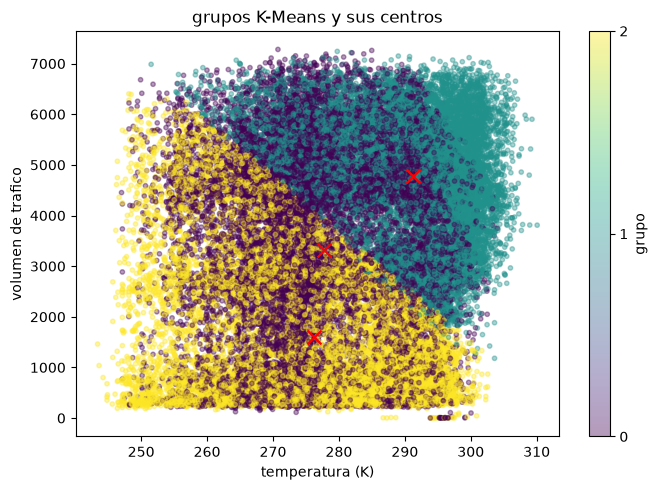

In [5]:
centros = escalador.inverse_transform(modelo.cluster_centers_)

plt.figure(figsize=(7, 5))
puntos = plt.scatter(
    datos["temp"], datos["traffic_volume"],
    c=datos["grupo"], cmap="viridis", alpha=0.4, s=10
)
plt.scatter(centros[:, 0], centros[:, 2], c="red", marker="x", s=100)
plt.colorbar(puntos, ticks=[0, 1, 2], label="grupo")
plt.xlabel("temperatura (K)")
plt.ylabel("volumen de trafico")
plt.title("grupos K-Means y sus centros")
plt.tight_layout()
plt.show()

El modelo obtuvo una silueta de 0,311
Los grupos tienen cierta separacion pero tambien presentan solapamiento
Los promedios muestran un grupo con mas nubes y otros dos con distinto volumen de trafico